# Exercise 1: Face Detection and Head Pose with MediaPipe

## 1. Setup: imports, paths, settings

In [1]:
import math
import urllib.request
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np
import pandas as pd
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# Find the course project folder by walking up from wherever this notebook runs until we hit the
# folder that contains DATA7800_YOLO. No machine-specific absolute paths, and the notebook can live
# in computer-vision/ or computer-vision/assignment/.
PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "DATA7800_YOLO").exists())
BASE_DIR = PROJECT_DIR / "computer-vision"     # shared models/ and outputs/ for all four exercises
IMAGE_ROOT = PROJECT_DIR / "DATA7800_YOLO" / "images_123rf"        # hashed folders: 0/00/*.jpg ... F/FF/*.jpg
FLAG_DIR = PROJECT_DIR / "DATA7800_YOLO" / "sorted_images" / "multi_flag" / "images"
MODEL_DIR = BASE_DIR / "models"
OUT_DIR = BASE_DIR / "outputs"
CROP_DIR = OUT_DIR / "ex1_face_crops"
ANNOTATED_DIR = OUT_DIR / "ex1_annotated"
for d in (MODEL_DIR, OUT_DIR, CROP_DIR, ANNOTATED_DIR):
    d.mkdir(parents=True, exist_ok=True)

LIMIT = None          # set to e.g. 100 while experimenting; None = all images
N_ANNOTATE = 40       # how many annotated example images to save
MAX_FACES = 5         # the starter used num_faces=1; stock photos often have several people
YAW_THRESHOLD = 15    # degrees; beyond this a face counts as turned left/right
PITCH_THRESHOLD = 15  # degrees; beyond this a face counts as tilted up/down

# Display size for previews (from the starter)
DESIRED_HEIGHT = 360
DESIRED_WIDTH = 360

## 2. Helpers: local display and folder walking
`cv2_imshow` only exists in Colab, so `resize_and_show` now uses matplotlib. OpenCV stores pixels as BGR and matplotlib expects RGB, so we convert before showing.

`list_images` walks the hashed folder structure, following the same logic as `yolo/walk_hashed_directory.py`.

In [2]:
def resize_and_show(image, title=None):
    # Same resizing logic as the starter, with matplotlib instead of cv2_imshow
    h, w = image.shape[:2]
    if h < w:
        img = cv2.resize(image, (DESIRED_WIDTH, math.floor(h / (w / DESIRED_WIDTH))))
    else:
        img = cv2.resize(image, (math.floor(w / (h / DESIRED_HEIGHT)), DESIRED_HEIGHT))
    plt.figure(figsize=(4, 4))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    if title:
        plt.title(title, fontsize=8)
    plt.show()


def list_images(root, limit=None):
    # Walk root/<0-F>/<00-FF>/*.jpg, skipping any stray non-directory files
    paths = []
    for folder in sorted(p for p in root.iterdir() if p.is_dir()):
        for subfolder in sorted(p for p in folder.iterdir() if p.is_dir()):
            paths.extend(sorted(subfolder.glob("*.jpg")))
    return paths[:limit] if limit else paths


def image_id(path):
    # 123rf filenames start with a numeric stock ID: "41754994-surgeon-with-usa-...jpg".
    # Using just the ID keeps output filenames short (long OneDrive paths can break on Windows).
    return path.stem.split("-")[0]


image_paths = list_images(IMAGE_ROOT, LIMIT)
print(f"Found {len(image_paths)} images under {IMAGE_ROOT}")

Found 1797 images under c:\Users\richa\OneDrive\Documents\Graduate Center\AI & ML for Artists and Humanists\DATA7800_YOLO\images_123rf


## 3. Download the MediaPipe models
These are the same two model files the starter downloads. They are skipped if already present.

In [3]:
MODELS = {
    "selfie_segmenter.tflite": "https://storage.googleapis.com/mediapipe-models/image_segmenter/selfie_segmenter/float16/latest/selfie_segmenter.tflite",
    "face_landmarker.task": "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/latest/face_landmarker.task",
}
for filename, url in MODELS.items():
    target = MODEL_DIR / filename
    if not target.exists():
        print(f"Downloading {filename} ...")
        urllib.request.urlretrieve(url, target)
    print(f"{filename}: {target.stat().st_size / 1e6:.1f} MB")

segmenter_model = str(MODEL_DIR / "selfie_segmenter.tflite")
landmarker_model = str(MODEL_DIR / "face_landmarker.task")

selfie_segmenter.tflite: 0.2 MB
face_landmarker.task: 3.8 MB


## 4. Canonical pattern, part 1: selfie segmentation (demo on a few images)
The starter is inconsistent about which `category_mask` value means "person". Cell 7 treats `mask > 0.2` as the figure, while cells 9 and 11 invert the mask (`1 - mask/255`). Instead of guessing, we also ask for the **confidence mask**, the model's 0–1 "person" probability, and check which category value agrees with it.

In [4]:
seg_options = vision.ImageSegmenterOptions(
    base_options=python.BaseOptions(model_asset_path=segmenter_model),
    output_category_mask=True,
    output_confidence_masks=True,   # added: per-pixel person probability, unambiguous
)


def to_mp_image(bgr):
    # OpenCV BGR -> RGB -> MediaPipe Image (same as the starter)
    return mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))


demo_paths = image_paths[:3]
demo_images = {p.name: cv2.imread(str(p)) for p in demo_paths}

with vision.ImageSegmenter.create_from_options(seg_options) as segmenter:
    result = segmenter.segment(to_mp_image(demo_images[demo_paths[0].name]))
    category = np.squeeze(result.category_mask.numpy_view())
    person_prob = np.squeeze(result.confidence_masks[0].numpy_view())

# Which category value lines up with "high person probability"?
values = np.unique(category)
for v in values:
    print(f"category value {v}: mean person probability = {person_prob[category == v].mean():.2f}")
PERSON_VALUE = max(values, key=lambda v: person_prob[category == v].mean())
print("=> the person is category value", PERSON_VALUE)

category value 0: mean person probability = 0.99
category value 255: mean person probability = 0.00
=> the person is category value 0


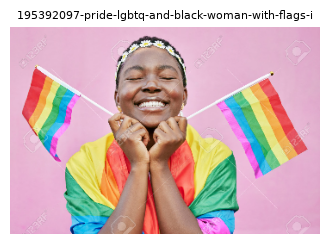

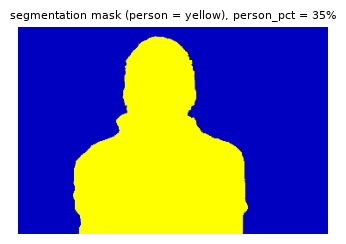

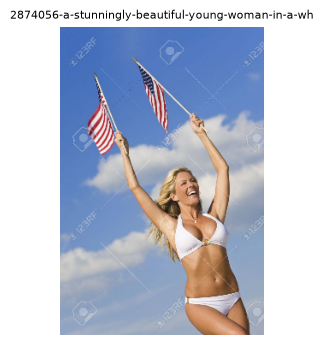

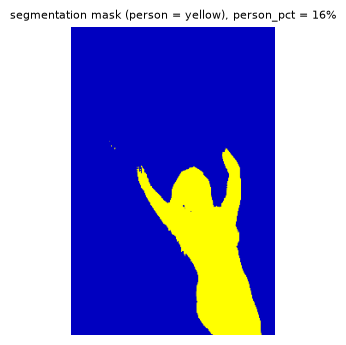

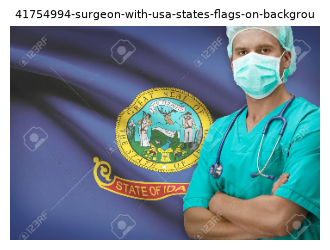

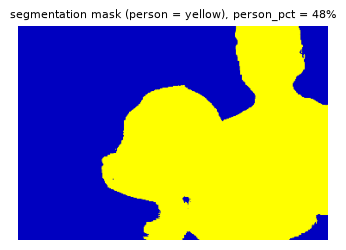

In [5]:
def person_mask(segmenter, bgr):
    # Returns a float mask in [0, 1] where 1 = person. Uses the confidence mask, which avoids
    # the category-value ambiguity and gives soft edges for nicer blending.
    result = segmenter.segment(to_mp_image(bgr))
    return np.squeeze(result.confidence_masks[0].numpy_view()).astype(float)


FIG_COLOR = (192, 0, 0)     # background colour in the mask preview (BGR)
MASK_COLOR = (0, 255, 255)  # person colour in the mask preview (yellow)

with vision.ImageSegmenter.create_from_options(seg_options) as segmenter:
    demo_masks = {name: person_mask(segmenter, img) for name, img in demo_images.items()}

for name, img in demo_images.items():
    mask3 = np.stack([demo_masks[name]] * 3, axis=-1) > 0.5
    preview = np.where(mask3, np.full(img.shape, MASK_COLOR, np.uint8), np.full(img.shape, FIG_COLOR, np.uint8))
    resize_and_show(img, name[:50])
    resize_and_show(preview, f"segmentation mask (person = yellow), person_pct = {(demo_masks[name] > 0.5).mean():.0%}")

## 5. Canonical pattern, part 2: background blur and composite
Same idea as the starter, with one fix. The starter composites using the *last* image's mask and a background resized to the *first* image, which only works with a single image. Here each image uses its own mask, and the background is resized to that image. For the new background we use a flag image from the YOLO flag dataset.

Background: France_0.png


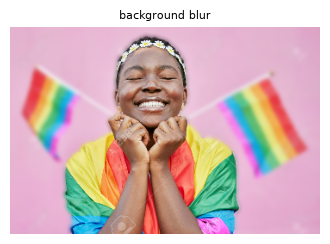

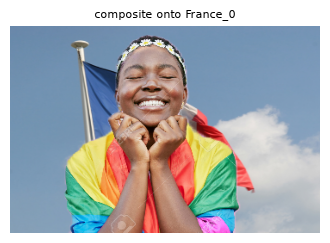

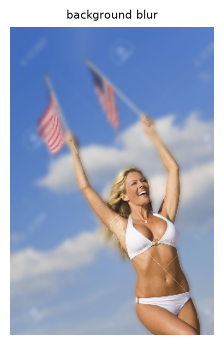

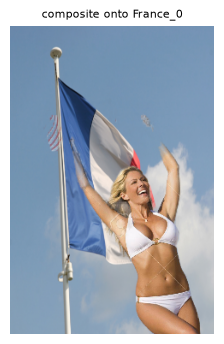

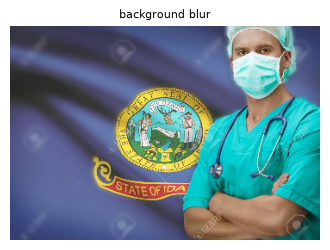

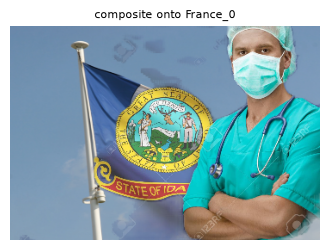

In [6]:
def blur_background(img, mask):
    m3 = np.stack([mask] * 3, axis=-1)                 # (H, W) -> (H, W, 3)
    blurred = cv2.GaussianBlur(img, (55, 55), 0)
    return (img * m3 + blurred * (1 - m3)).astype(np.uint8)


def composite(img, mask, background):
    bg = cv2.resize(background, (img.shape[1], img.shape[0]))  # size the background to THIS image
    m3 = np.stack([mask] * 3, axis=-1)
    return (img * m3 + bg * (1 - m3)).astype(np.uint8)


flag_files = sorted(FLAG_DIR.glob("France_*.png")) or sorted(FLAG_DIR.glob("*.png"))
flag_bg = cv2.imread(str(flag_files[0]))
print("Background:", flag_files[0].name)

for name, img in demo_images.items():
    resize_and_show(blur_background(img, demo_masks[name]), "background blur")
    resize_and_show(composite(img, demo_masks[name], flag_bg), f"composite onto {flag_files[0].stem}")

## 6. Canonical pattern, part 3: face mesh, plus head pose (new)
The starter's `FaceLandmarker` had `num_faces=1` and `output_facial_transformation_matrixes=False`. We raise the face count and turn the matrix on. The matrix is a 4×4 transform from a canonical, front-facing face to the detected face. Its top-left 3×3 block is a rotation, which we convert to Euler angles:
- **yaw**: turning left/right (shaking your head "no")
- **pitch**: tilting up/down (nodding "yes")
- **roll**: tilting the head sideways towards a shoulder

Sign conventions are easy to get backwards, so we check yaw against a simple geometric cue: where the nose tip sits between the two sides of the face. Labels are written from the **viewer's** point of view ("turned toward image left") to avoid subject/viewer confusion.

In [7]:
lm_options = vision.FaceLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=landmarker_model),
    output_face_blendshapes=False,
    output_facial_transformation_matrixes=True,   # changed: needed for head pose
    num_faces=MAX_FACES,                          # changed: was 1
)

NOSE_TIP, FACE_LEFT_EDGE, FACE_RIGHT_EDGE = 1, 234, 454   # MediaPipe face-mesh landmark indices


def matrix_to_euler(matrix):
    # Rotation matrix -> (yaw, pitch, roll) in degrees
    R = np.asarray(matrix)[:3, :3]
    pitch = math.degrees(math.atan2(R[2, 1], R[2, 2]))
    yaw = math.degrees(math.atan2(-R[2, 0], math.hypot(R[2, 1], R[2, 2])))
    roll = math.degrees(math.atan2(R[1, 0], R[0, 0]))
    return yaw, pitch, roll


def nose_offset(landmarks):
    # Geometric sanity check: -1 = nose at the image-left edge of the face, +1 = image-right edge
    left, right, nose = landmarks[FACE_LEFT_EDGE].x, landmarks[FACE_RIGHT_EDGE].x, landmarks[NOSE_TIP].x
    centre, half_width = (left + right) / 2, abs(right - left) / 2 or 1e-6
    return (nose - centre) / half_width

### Calibrating the yaw sign
We run the landmarker on a sample of images and compare yaw with the nose offset. If they move in opposite directions, we flip the sign so that **positive yaw = face turned toward image right**.

In [8]:
calib = []
with vision.FaceLandmarker.create_from_options(lm_options) as landmarker:
    for p in image_paths[:150]:
        img = cv2.imread(str(p))
        if img is None:
            continue
        res = landmarker.detect(to_mp_image(img))
        for lms, mat in zip(res.face_landmarks, res.facial_transformation_matrixes):
            yaw, pitch, roll = matrix_to_euler(mat)
            calib.append((yaw, nose_offset(lms)))

calib = np.array(calib)
corr = np.corrcoef(calib[:, 0], calib[:, 1])[0, 1]
YAW_SIGN = 1 if corr > 0 else -1
print(f"{len(calib)} faces; correlation(yaw, nose offset) = {corr:.2f} -> YAW_SIGN = {YAW_SIGN}")

95 faces; correlation(yaw, nose offset) = 0.96 -> YAW_SIGN = 1


Pitch is harder to check automatically. Look at the annotated images saved in section 7 and confirm that "up" and "down" match what you see. If they are backwards, set `PITCH_SIGN = -1`.

In [9]:
PITCH_SIGN = 1


def head_pose(matrix):
    yaw, pitch, roll = matrix_to_euler(matrix)
    return YAW_SIGN * yaw, PITCH_SIGN * pitch, roll


def pose_label(yaw, pitch):
    # Simple human-readable label, from the viewer's point of view
    parts = []
    if pitch > PITCH_THRESHOLD:
        parts.append("up")
    elif pitch < -PITCH_THRESHOLD:
        parts.append("down")
    if yaw > YAW_THRESHOLD:
        parts.append("toward image right")
    elif yaw < -YAW_THRESHOLD:
        parts.append("toward image left")
    return ", ".join(parts) or "frontal"


def face_box(landmarks, w, h, pad=0.0):
    # Bounding box from landmark extremes, optionally padded (the starter used 50% padding for crops)
    xs = [lm.x * w for lm in landmarks]
    ys = [lm.y * h for lm in landmarks]
    x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys)
    px, py = (x2 - x1) * pad, (y2 - y1) * pad
    return (max(0, int(x1 - px)), max(0, int(y1 - py)), min(w, int(x2 + px)), min(h, int(y2 + py)))


def annotate(img, faces):
    # Draw landmarks, box and pose label for each face
    out = img.copy()
    h, w = out.shape[:2]
    for f in faces:
        for lm in f["landmarks"]:
            cv2.circle(out, (int(lm.x * w), int(lm.y * h)), 1, (0, 255, 0), -1)
        x1, y1, x2, y2 = f["box"]
        cv2.rectangle(out, (x1, y1), (x2, y2), (0, 200, 255), 2)
        text = f"{f['label']} (y{f['yaw']:+.0f} p{f['pitch']:+.0f} r{f['roll']:+.0f})"
        cv2.putText(out, text, (x1, max(15, y1 - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 200, 255), 2)
    return out

## 7. The batch pipeline
For every image we run both models, then record:
- `person_pct`: the share of pixels the segmenter thinks are a person
- `n_faces`: how many faces the landmarker found
- one row per face with its bounding box, yaw, pitch, roll, pose label and crop filename

Images with **no** face still get a row (with empty face columns), so we can study the misses.

In [10]:
rows = []
n_annotated = 0

with vision.ImageSegmenter.create_from_options(seg_options) as segmenter, \
     vision.FaceLandmarker.create_from_options(lm_options) as landmarker:
    for i, path in enumerate(image_paths):
        img = cv2.imread(str(path))
        if img is None:
            print("Could not read", path)
            continue
        h, w = img.shape[:2]
        rel_path = path.relative_to(PROJECT_DIR / "DATA7800_YOLO").as_posix()
        base = {"image_path": rel_path, "image_id": image_id(path), "width": w, "height": h}

        # Segmentation: how much of the frame is "person"?
        base["person_pct"] = round(float((person_mask(segmenter, img) > 0.5).mean()), 4)

        # Face landmarks + head pose
        res = landmarker.detect(to_mp_image(img))
        base["n_faces"] = len(res.face_landmarks)

        faces = []
        for j, (lms, mat) in enumerate(zip(res.face_landmarks, res.facial_transformation_matrixes)):
            yaw, pitch, roll = head_pose(mat)
            box = face_box(lms, w, h)
            x1, y1, x2, y2 = face_box(lms, w, h, pad=0.5)           # padded crop, as in the starter
            crop_name = f"{base['image_id']}_face{j}.jpg"
            cv2.imwrite(str(CROP_DIR / crop_name), img[y1:y2, x1:x2])
            face = {"face_idx": j, "box": box, "yaw": yaw, "pitch": pitch, "roll": roll,
                    "label": pose_label(yaw, pitch), "landmarks": lms}
            faces.append(face)
            rows.append({**base, "face_idx": j,
                         "x1": box[0], "y1": box[1], "x2": box[2], "y2": box[3],
                         "face_area_pct": round((box[2] - box[0]) * (box[3] - box[1]) / (w * h), 4),
                         "yaw": round(yaw, 1), "pitch": round(pitch, 1), "roll": round(roll, 1),
                         "pose_label": face["label"], "nose_offset": round(nose_offset(lms), 3),
                         "crop_file": crop_name})
        if not faces:
            rows.append(base)

        if faces and n_annotated < N_ANNOTATE:
            cv2.imwrite(str(ANNOTATED_DIR / f"{base['image_id']}.jpg"), annotate(img, faces))
            n_annotated += 1

        if (i + 1) % 200 == 0:
            print(f"{i + 1}/{len(image_paths)} images processed")

df = pd.DataFrame(rows)
df.to_csv(OUT_DIR / "ex1_faces.csv", index=False)
print(f"Saved {len(df)} rows to {OUT_DIR / 'ex1_faces.csv'}")
df.head()

200/1797 images processed
400/1797 images processed
600/1797 images processed
800/1797 images processed
1000/1797 images processed
1200/1797 images processed
1400/1797 images processed
1600/1797 images processed
Saved 1830 rows to c:\Users\richa\OneDrive\Documents\Graduate Center\AI & ML for Artists and Humanists\computer-vision\outputs\ex1_faces.csv


,image_path,image_id,width,height,person_pct,n_faces,face_idx,x1,y1,x2,y2,face_area_pct,yaw,pitch,roll,pose_label,nose_offset,crop_file
0,images_123rf/0/00/195392097-pride-lgbtq-and-bl...,195392097,1300,867,0.3497,1,0.0,458.0,129.0,727.0,415.0,0.0683,1.7,-10.1,0.9,frontal,0.013,195392097_face0.jpg
1,images_123rf/0/00/2874056-a-stunningly-beautif...,2874056,866,1300,0.1608,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,images_123rf/0/00/41754994-surgeon-with-usa-st...,41754994,1300,898,0.4804,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,images_123rf/0/00/54729503-thoughtful-woman-an...,54729503,1300,867,0.2379,1,0.0,581.0,142.0,750.0,330.0,0.0282,4.0,11.9,4.3,frontal,0.131,54729503_face0.jpg
4,images_123rf/0/00/9239997-a-girl-is-blowing-on...,9239997,1144,1300,0.5909,1,0.0,354.0,322.0,694.0,718.0,0.0905,54.3,28.9,22.0,"up, toward image right",2.108,9239997_face0.jpg


## 8. What did we find?

In [11]:
per_image = df.drop_duplicates("image_path")
print(f"Images processed:          {len(per_image)}")
print(f"Images with >=1 face:      {(per_image.n_faces > 0).sum()} ({(per_image.n_faces > 0).mean():.0%})")
print(f"Faces detected:            {int(df.face_idx.notna().sum())}")
print(f"Faces saved as crops:      {len(list(CROP_DIR.glob('*.jpg')))}")
print()
print("Faces per image:")
print(per_image.n_faces.value_counts().sort_index().to_string())
print()
print("Pose labels:")
print(df.pose_label.value_counts().to_string())

Images processed:          1797
Images with >=1 face:      1227 (68%)
Faces detected:            1260
Faces saved as crops:      1260

Faces per image:
n_faces
0     570
1    1209
2       7
3       9
5       2

Pose labels:
pose_label
frontal                     714
toward image left           196
up                          149
toward image right           83
up, toward image left        46
up, toward image right       36
down                         21
down, toward image left      13
down, toward image right      2


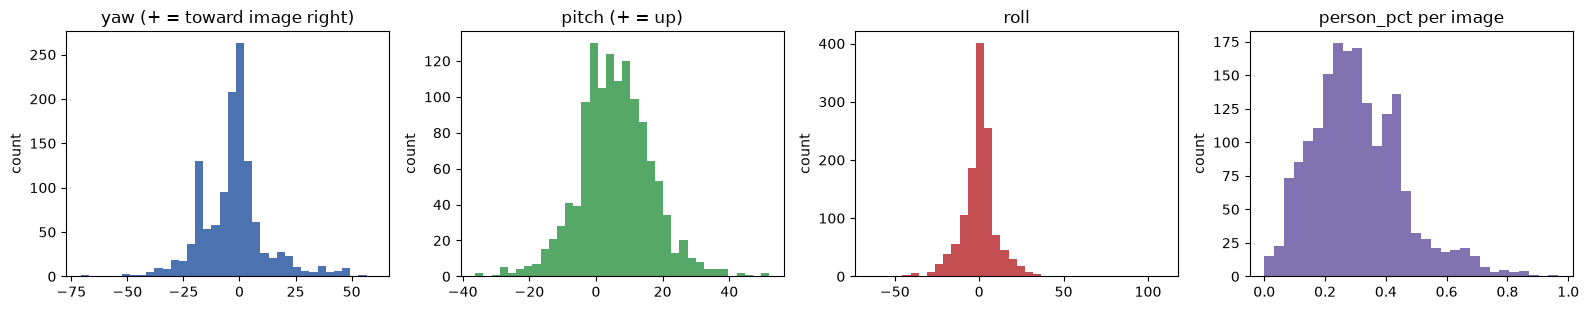

In [12]:
faces_df = df[df.face_idx.notna()]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
axes[0].hist(faces_df.yaw, bins=36, color="#4C72B0"); axes[0].set_title("yaw (+ = toward image right)")
axes[1].hist(faces_df.pitch, bins=36, color="#55A868"); axes[1].set_title("pitch (+ = up)")
axes[2].hist(faces_df.roll, bins=36, color="#C44E52"); axes[2].set_title("roll")
axes[3].hist(per_image.person_pct, bins=30, color="#8172B2"); axes[3].set_title("person_pct per image")
for ax in axes:
    ax.set_ylabel("count")
plt.tight_layout()
plt.show()

## 9. Breakdown test: where does it fail?
Disagreement between the two models is a useful signal. If the **segmenter** says a large part of the frame is a person but the **landmarker** finds no face, something is hiding or distorting the face: a flag held in front of it, face paint, a profile view, or sunglasses. The reverse (faces but almost no "person") points to faces printed on objects, or segmentation failing.

150 images where >25% of the frame is 'person' but no face was found


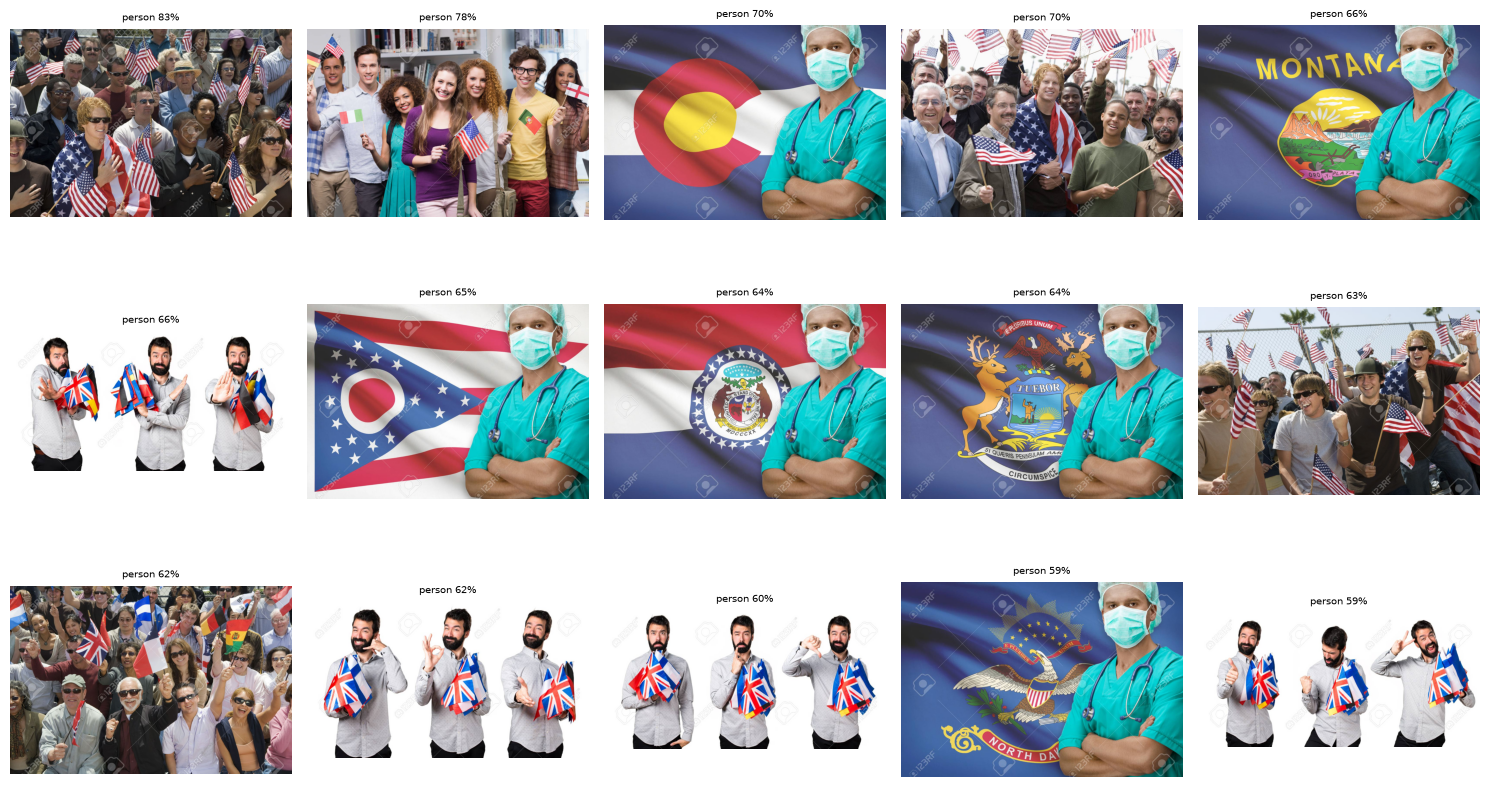

In [13]:
def contact_sheet(paths, titles, cols=5, size=3):
    if not paths:
        print("(none)")
        return
    rows_n = math.ceil(len(paths) / cols)
    fig, axes = plt.subplots(rows_n, cols, figsize=(cols * size, rows_n * size))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for ax, p, t in zip(np.atleast_1d(axes).ravel(), paths, titles):
        img = cv2.imread(str(p))
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(t, fontsize=7)
    plt.tight_layout()
    plt.show()


DATA_DIR = PROJECT_DIR / "DATA7800_YOLO"
missed = per_image[(per_image.n_faces == 0) & (per_image.person_pct > 0.25)].sort_values("person_pct", ascending=False)
print(f"{len(missed)} images where >25% of the frame is 'person' but no face was found")
contact_sheet([DATA_DIR / p for p in missed.image_path.head(15)],
              [f"person {v:.0%}" for v in missed.person_pct.head(15)])

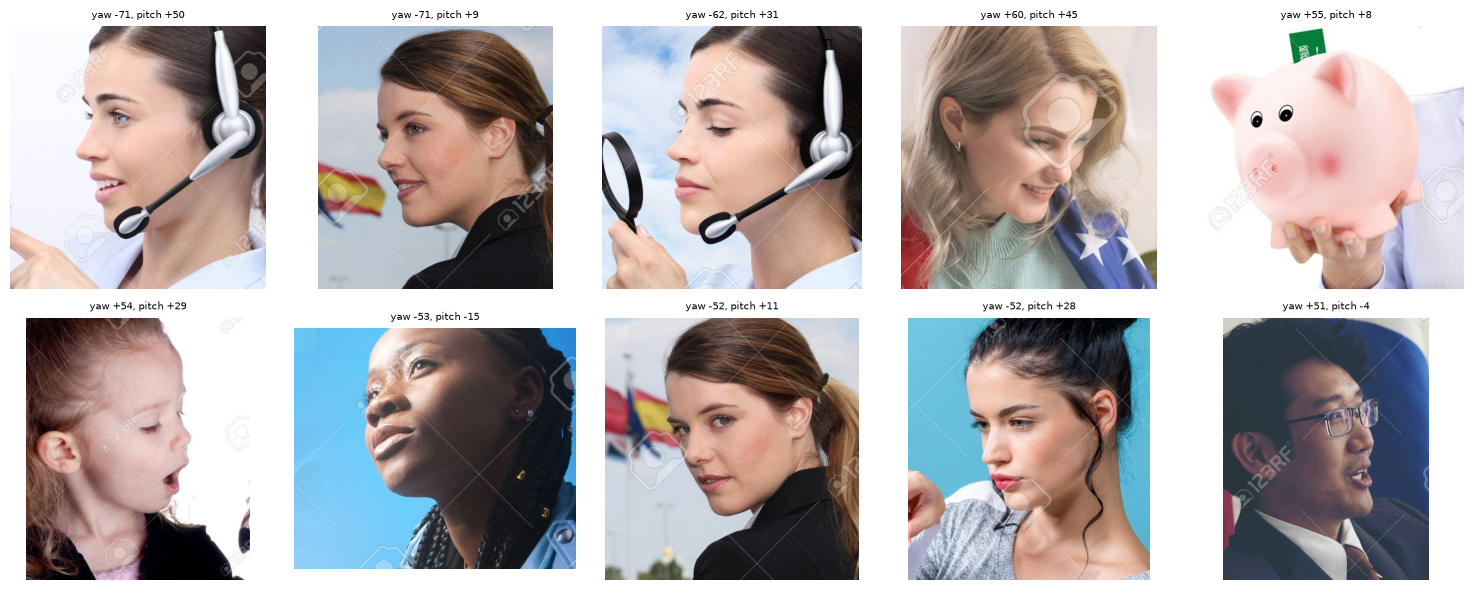

In [14]:
# The most extreme head poses: are they real, or landmarker mistakes?
extreme = faces_df.reindex(faces_df.yaw.abs().sort_values(ascending=False).index).head(10)
contact_sheet([CROP_DIR / f for f in extreme.crop_file],
              [f"yaw {y:+.0f}, pitch {p:+.0f}" for y, p in zip(extreme.yaw, extreme.pitch)])

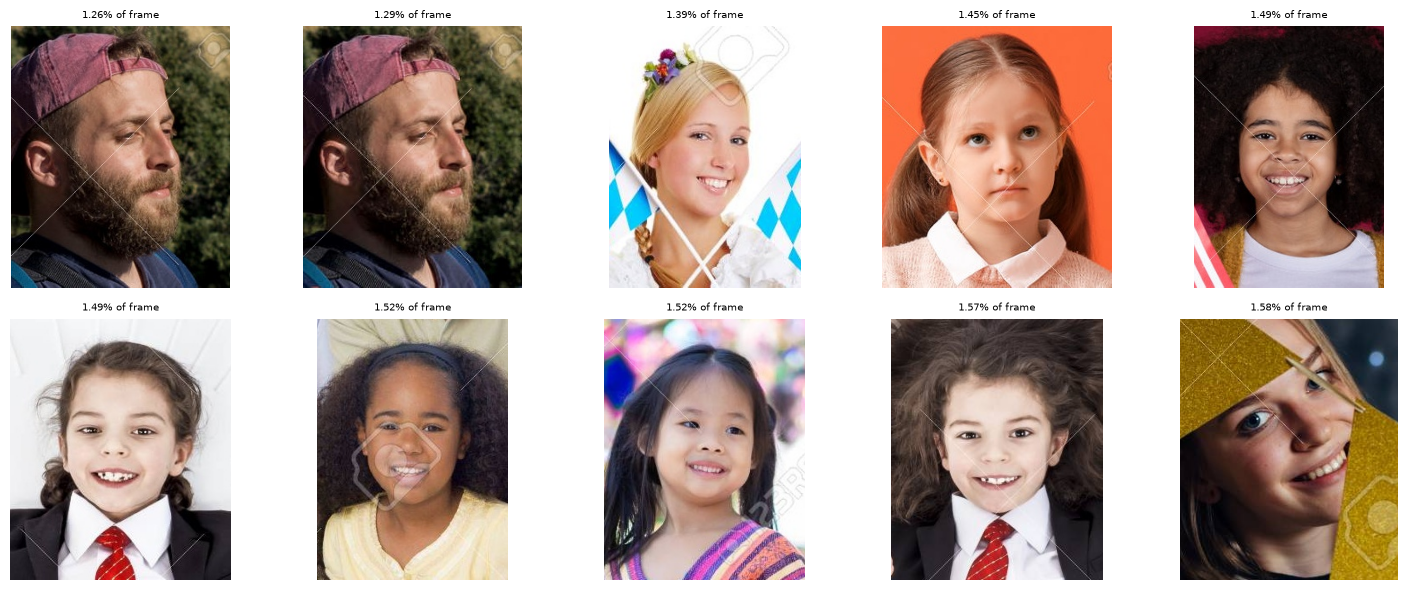

In [15]:
# The smallest detected faces: crowds and background figures, likely where precision drops
small = faces_df.sort_values("face_area_pct").head(10)
contact_sheet([CROP_DIR / f for f in small.crop_file],
              [f"{a:.2%} of frame" for a in small.face_area_pct])

## 10. Reflection

- Crowds and small faces fail badly. Group shots with many clear faces return zero faces. The smallest face found anywhere is about 1.3% of the frame, and only 18 images had more than one face. The face finder built into FaceLandmarker is designed for selfie distance, so the face count means "large faces", not "number of people".
- Surgical masks are missed too. The masked-surgeon series accounts for many of the 150 images that are mostly person but have no face.